# 6. A Raman soft sensor

The lab reports PAA every 12 h, too slowly for tight control. A Raman probe gives a spectrum every 12 minutes. A
**soft sensor** turns spectra into concentration estimates. This notebook calibrates one the way a plant would: on
past batches, against the lab results only, and then tests it on new batches.

**You need:** scikit-learn and SciPy. The spectra take about 20 MB per batch in memory.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

from scipy.signal import savgol_filter
from sklearn.cross_decomposition import PLSRegression

from penicillium import scenarios

camp = scenarios.soft_sensor_campaign(n_batches=8, seed=0)
print(len(camp.raman), "batches;", camp.raman[1].shape, "spectra per batch;", len(camp.lab), "lab results")
camp.lab.head()

8 batches; (1150, 2200) spectra per batch; 168 lab results


,batch_id,sample_time_h,available_time_h,P,X,PAA,NH3,Viscosity
0,1,0.2,1.0,0.001000,0.481590,1314.476772,1730.310336,4.080538
1,1,11.2,12.0,0.000969,3.200918,1414.134360,1850.737751,10.931270
2,1,23.2,24.0,0.000917,9.367711,1103.664240,1849.179340,22.004277
3,1,35.2,36.0,1.997703,13.096894,533.748087,1741.382098,35.553447
4,1,47.2,48.0,4.806365,16.427427,440.051432,1753.467977,49.700664


## Calibration data

Each lab result was taken from the broth at `sample_time_h`. The matching spectrum is the one recorded in that
sample. Spectra start at 2 h, so the 1 h lab result has no spectrum.

In [2]:
def row(t):  # sample index of a time in hours (samples end at 0.2, 0.4, ... h)
    return round(t / 0.2) - 1


def features(spectra):
    # first derivative (removes the slowly varying fluorescence baseline), on a smoothed spectrum
    return savgol_filter(spectra, window_length=25, polyorder=2, deriv=1, axis=-1)


lab = camp.lab[camp.lab.sample_time_h >= 2.2]
batches = sorted(camp.raman)
train_b, test_b = batches[:6], batches[6:]


def xy(ids):
    sub = lab[lab.batch_id.isin(ids)]
    X = np.array([camp.raman[b][row(t)] for b, t in zip(sub.batch_id, sub.sample_time_h)])
    return features(X), sub.PAA.to_numpy()


X_train, y_train = xy(train_b)
print("calibration set:", X_train.shape)

calibration set: (120, 2200)


## Choose the model size by 10-fold cross-validation

The folds are drawn over the 120 calibration samples, not over batches, so samples of one batch fall on both
sides of a fold. The cross-validation error (RMSECV) is therefore optimistic as an estimate for a new batch,
and the number of latent variables may be larger than a batch-wise choice would give. The figure to read is
the error on the two test batches below, which are not used in this choice. Leave-one-batch-out
cross-validation over the six calibration batches is the better choice and is planned for this tutorial.

chosen: 8 components, RMSECV 104 mg/L


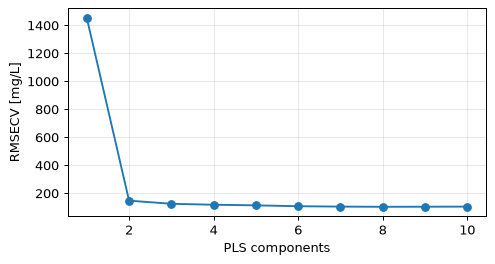

In [3]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=10, shuffle=True, random_state=0)
rmse = {}
for n in range(1, 11):
    errs = [
        PLSRegression(n_components=n).fit(X_train[a], y_train[a]).predict(X_train[b]).ravel() - y_train[b]
        for a, b in kf.split(X_train)
    ]
    rmse[n] = np.sqrt(np.mean(np.concatenate(errs) ** 2))
rmse = pd.Series(rmse, name="RMSECV [mg/L]")
ax = rmse.plot(marker="o", figsize=(6, 3))
ax.set(xlabel="PLS components", ylabel="RMSECV [mg/L]")
n_best = int(rmse.idxmin())
print(f"chosen: {n_best} components, RMSECV {rmse[n_best]:.0f} mg/L")

## Test on new batches

The model is applied to every spectrum of the two test batches and compared with the true PAA, which a plant would
not know, and with the lab results it would.

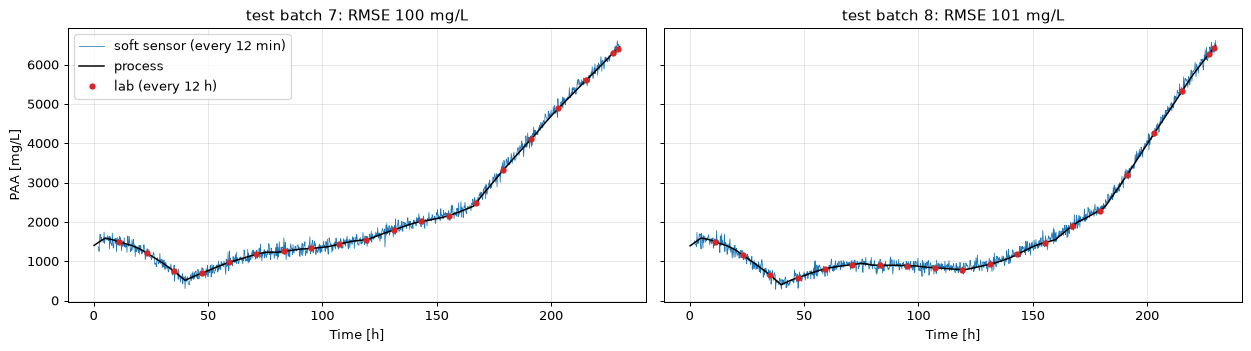

In [4]:
pls = PLSRegression(n_components=n_best).fit(X_train, y_train)

fig, axes = plt.subplots(1, len(test_b), figsize=(14, 4), sharey=True)
for ax, b in zip(np.atleast_1d(axes), test_b):
    samples = camp.samples[camp.samples.batch_id == b]
    pred = pls.predict(features(camp.raman[b][10:])).ravel()
    true = samples.PAA.to_numpy()[10:]
    ax.plot(samples.time_h.to_numpy()[10:], pred, lw=0.6, label="soft sensor (every 12 min)")
    ax.plot(samples.time_h, samples.PAA, color="k", lw=1.2, label="process")
    l = lab[lab.batch_id == b]
    ax.plot(l.sample_time_h, l.PAA, "o", color="tab:red", ms=4, label="lab (every 12 h)")
    err = np.sqrt(np.mean((pred - true) ** 2))
    ax.set(xlabel="Time [h]", title=f"test batch {b}: RMSE {err:.0f} mg/L")
np.atleast_1d(axes)[0].set_ylabel("PAA [mg/L]")
np.atleast_1d(axes)[0].legend()
fig.tight_layout()

The estimate follows the process between lab results, which is what a controller needs. The error on the two
test batches (about 100 mg/L) is a best case for a plant: the simulated spectra contain none of the common
artefacts of real Raman probes (cosmic-ray spikes, laser-power drift, wavenumber shift, probe fouling). To close the loop, feed the
prediction to a PAA controller with `Simulator.step` ([tutorial 2](02_recipes_and_control.ipynb)) and read each new
spectrum with `sim.latest_spectrum()`.

IndPenSim's own advanced-control mode (`RamanMode.PAT_CONTROL`) runs a PAA controller from 10 h and records a PLS
prediction in the channel `PAA_pred`; see [Lab data and Raman spectra](../measurements.md).

**Next:** [Reinforcement learning](07_reinforcement_learning.ipynb).